# Telco Customer Churn — Exploratory Data Analysis

**Goal:** find which customer characteristics, services and account features are associated with churn (customers who left in the last month), compare churn across segments, and suggest retention strategies.

**Dataset:** IBM Telco Customer Churn (Kaggle *blastchar/telco-customer-churn*): 7,043 customers, 21 columns.

**Tools:** pandas, NumPy, Matplotlib, Seaborn.

## 1. Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 25)
CHURN_COLORS = ['#4c72b0', '#dd5555']

df = pd.read_csv('data/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data cleaning
### 2.1 Data types and hidden missing values
`TotalCharges` is stored as text. Converting it to a number reveals blank strings.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df['TotalCharges'].isna().sum())
df[df['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All 11 blanks are brand-new customers with `tenure = 0`: they have not been billed yet, so their total charges are 0, not unknown.

In [5]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print('Missing values left:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())

Missing values left: 0
Duplicate rows: 0
Duplicate customer IDs: 0


### 2.2 Consistent categories

In [6]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['churn_flag'] = (df['Churn'] == 'Yes').astype(int)
for col in df.select_dtypes('object').columns.drop('customerID'):
    print(f'{col:17s}', sorted(df[col].unique()))

gender            ['Female', 'Male']
SeniorCitizen     ['No', 'Yes']
Partner           ['No', 'Yes']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No', 'No phone service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
StreamingTV       ['No', 'No internet service', 'Yes']
StreamingMovies   ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
PaymentMethod     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             ['No', 'Yes']


`No internet service` / `No phone service` are kept as their own categories, because customers without the base service cannot have the add-on.

In [7]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 60, 72],
                            labels=['0-12 m', '13-24 m', '25-48 m', '49-60 m', '61-72 m'])
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_addons'] = (df[addons] == 'Yes').sum(axis=1)
df[['tenure', 'tenure_group', 'num_addons']].head()

,tenure,tenure_group,num_addons
0,1,0-12 m,1
1,34,25-48 m,2
2,2,0-12 m,2
3,45,25-48 m,3
4,2,0-12 m,0


## 3. Descriptive statistics

In [8]:
df[['tenure', 'MonthlyCharges', 'TotalCharges', 'num_addons']].describe().round(2)

,tenure,MonthlyCharges,TotalCharges,num_addons
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,2.04
std,24.56,30.09,2266.79,1.85
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,2.00
75%,55.00,89.85,3786.60,3.00
max,72.00,118.75,8684.80,6.00


Overall churn rate: 26.5% (1869 of 7043 customers)


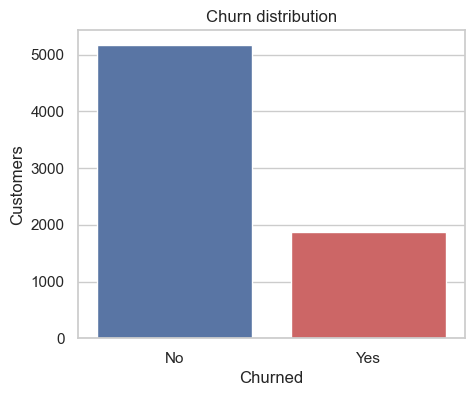

In [9]:
churn_rate = df['churn_flag'].mean()
print(f'Overall churn rate: {churn_rate:.1%} ({df.churn_flag.sum()} of {len(df)} customers)')
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='Churn', palette=CHURN_COLORS, hue='Churn', legend=False, ax=ax)
ax.set(title='Churn distribution', xlabel='Churned', ylabel='Customers')
plt.show()

In [10]:
df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges', 'num_addons']].agg(['mean', 'median']).round(1)

tenure        MonthlyCharges        TotalCharges         num_addons  \
        mean median           mean median         mean  median       mean   
Churn                                                                       
No      37.6   38.0           61.3   64.4       2549.9  1679.5        2.1   
Yes     18.0   10.0           74.4   79.6       1531.8   703.6        1.8   

              
      median  
Churn         
No       2.0  
Yes      2.0

## 4. Churn rate by segment
A helper computes the churn rate and size of every category, so segments can be compared directly.

In [11]:
def churn_by(col):
    t = df.groupby(col, observed=True)['churn_flag'].agg(customers='size', churn_rate='mean')
    t['churn_rate'] = (t['churn_rate'] * 100).round(1)
    t['vs_overall_pts'] = (t['churn_rate'] - churn_rate * 100).round(1)
    return t.sort_values('churn_rate', ascending=False)

def plot_rates(cols, title, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        t = churn_by(col)
        sns.barplot(x=t.index.astype(str), y=t['churn_rate'], ax=ax, color='#dd5555')
        ax.axhline(churn_rate * 100, ls='--', color='grey', lw=1)
        ax.set(title=col, xlabel='', ylabel='Churn rate (%)')
        ax.tick_params(axis='x', rotation=20)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

### 4.1 Demographics

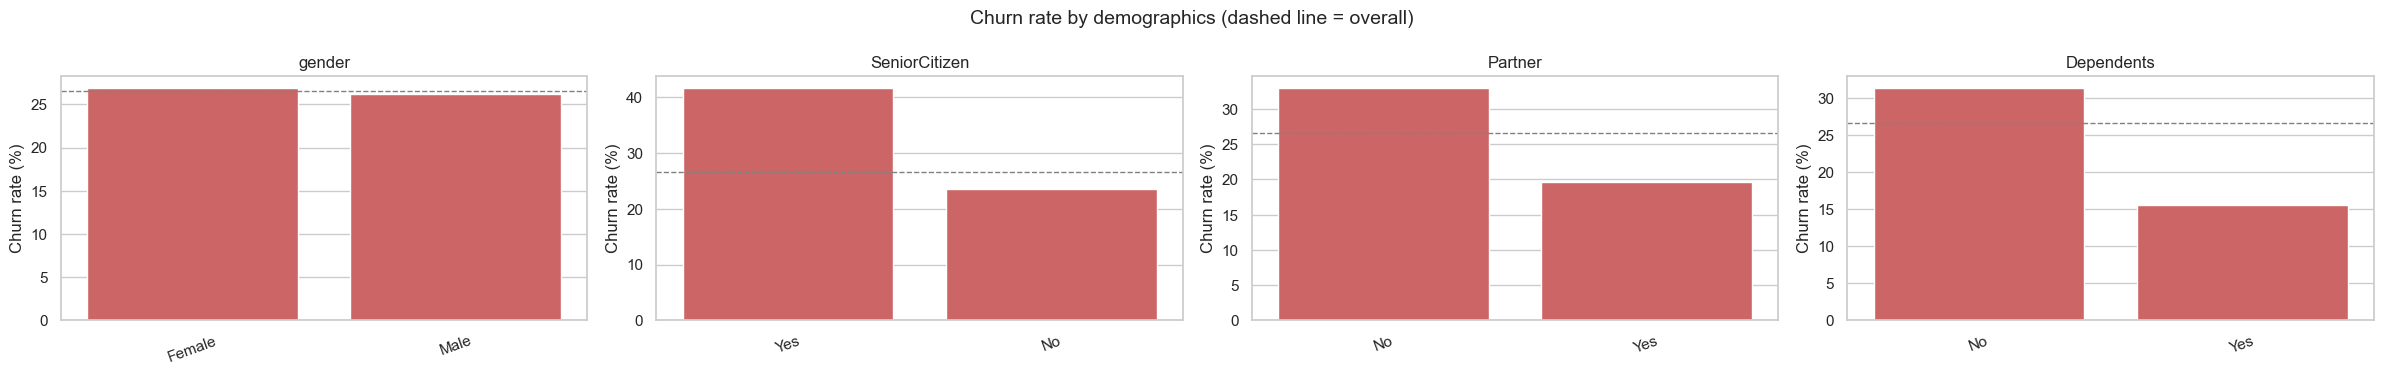

In [12]:
plot_rates(['gender', 'SeniorCitizen', 'Partner', 'Dependents'], 'Churn rate by demographics (dashed line = overall)', ncols=4)

In [13]:
pd.concat({c: churn_by(c) for c in ['gender', 'SeniorCitizen', 'Partner', 'Dependents']})

customers  churn_rate  vs_overall_pts
gender        Female       3488        26.9             0.4
              Male         3555        26.2            -0.3
SeniorCitizen Yes          1142        41.7            15.2
              No           5901        23.6            -2.9
Partner       No           3641        33.0             6.5
              Yes          3402        19.7            -6.8
Dependents    No           4933        31.3             4.8
              Yes          2110        15.5           -11.0

### 4.2 Contract, billing and payment

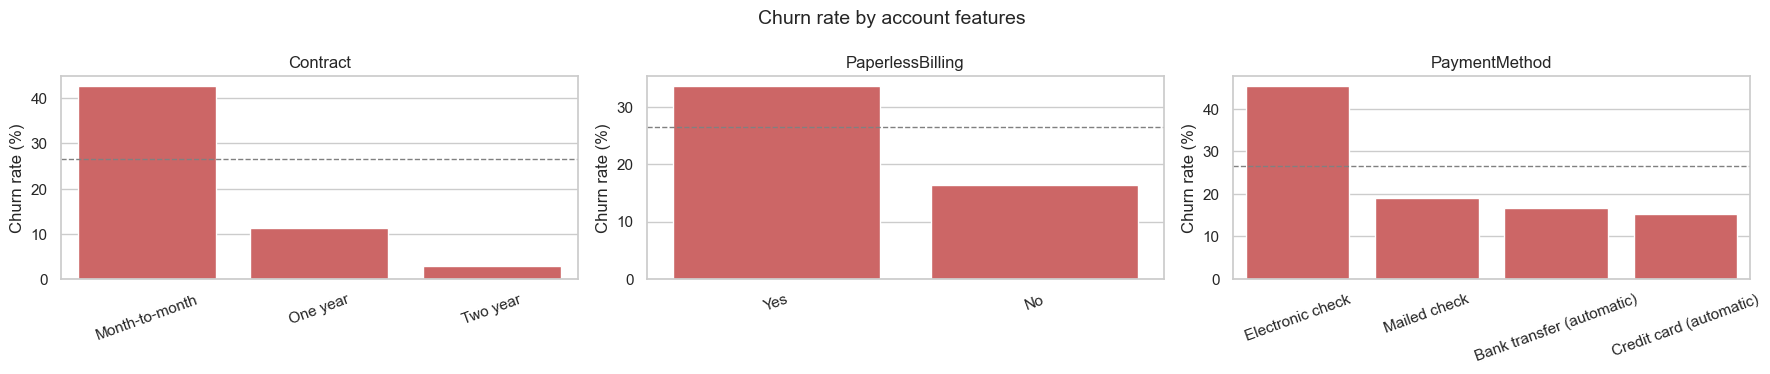

In [14]:
plot_rates(['Contract', 'PaperlessBilling', 'PaymentMethod'], 'Churn rate by account features')

In [15]:
pd.concat({c: churn_by(c) for c in ['Contract', 'PaperlessBilling', 'PaymentMethod']})

customers  churn_rate  \
Contract         Month-to-month                  3875        42.7   
                 One year                        1473        11.3   
                 Two year                        1695         2.8   
PaperlessBilling Yes                             4171        33.6   
                 No                              2872        16.3   
PaymentMethod    Electronic check                2365        45.3   
                 Mailed check                    1612        19.1   
                 Bank transfer (automatic)       1544        16.7   
                 Credit card (automatic)         1522        15.2   

                                            vs_overall_pts  
Contract         Month-to-month                       16.2  
                 One year                            -15.2  
                 Two year                            -23.7  
PaperlessBilling Yes                                   7.1  
                 No                                  -10.2  
PaymentMethod    Electronic check                     18.8  
                 Mailed check                         -7.4  
                 Bank transfer (automatic)            -9.8  
                 Credit card (automatic)             -11.3

### 4.3 Subscribed services

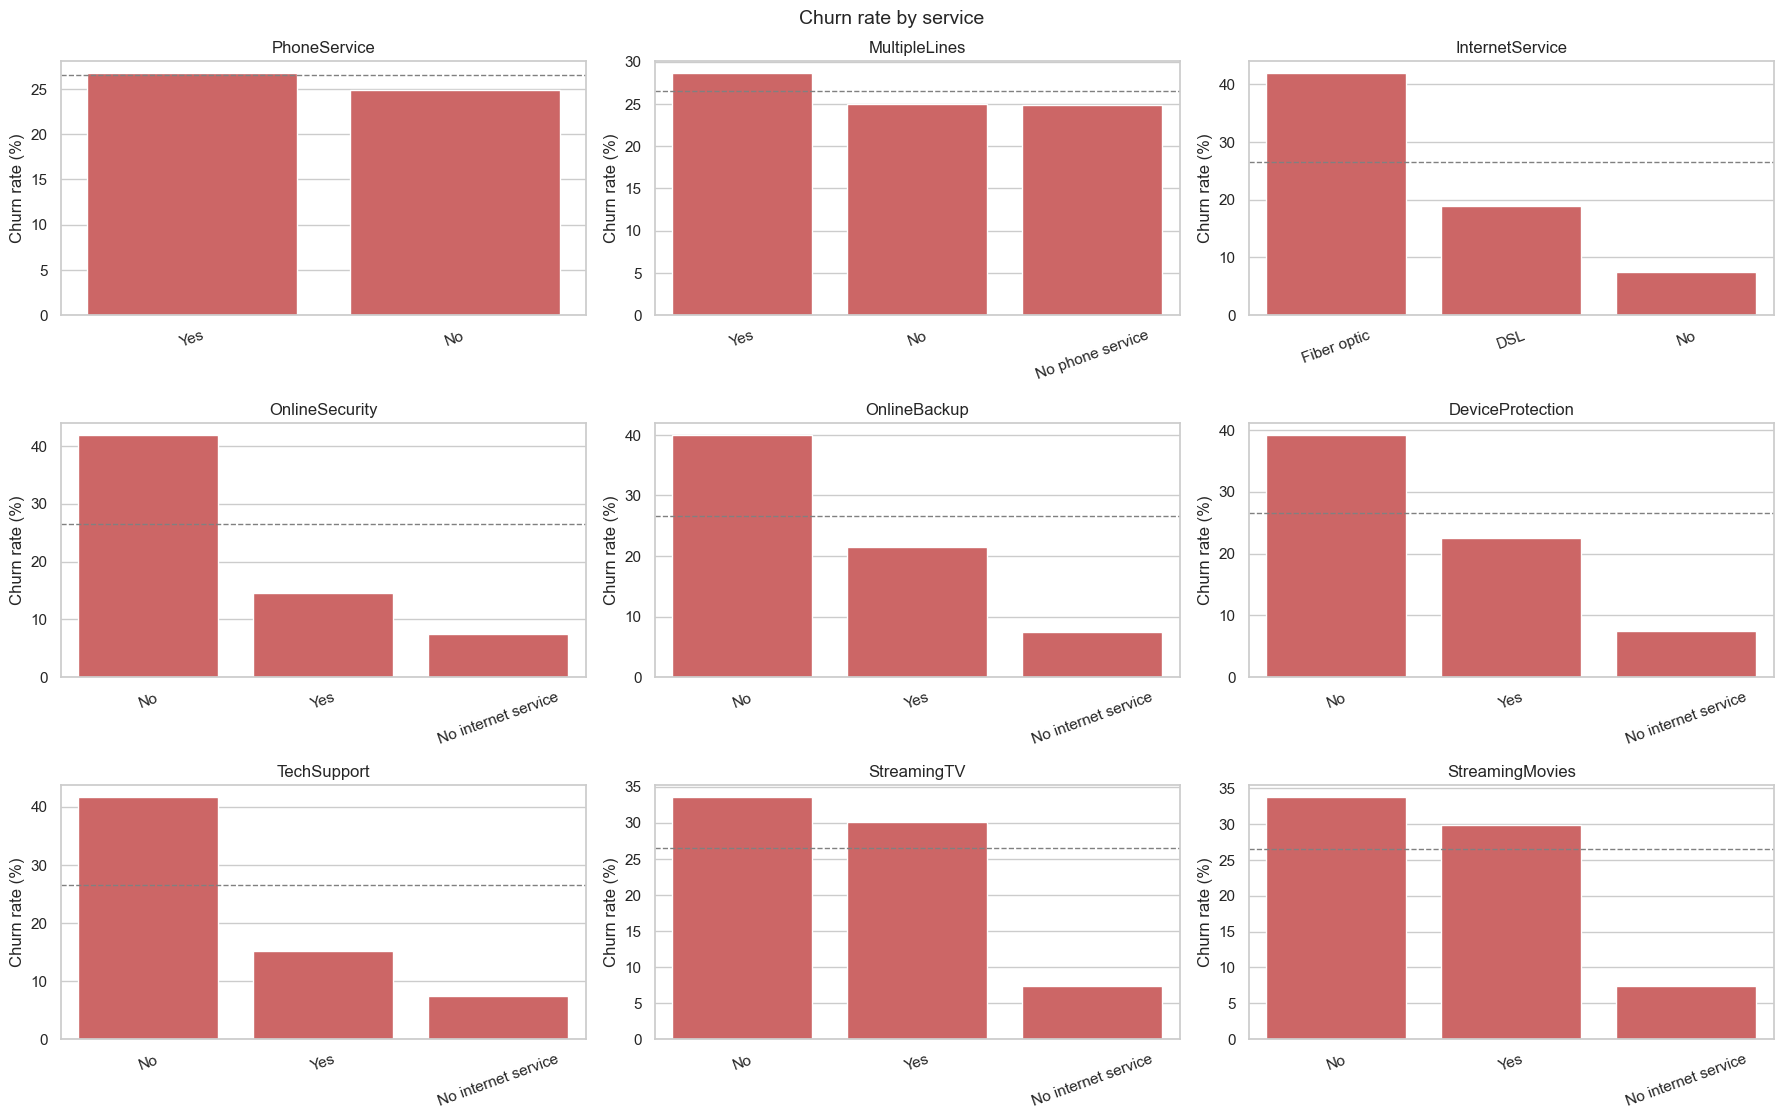

In [16]:
plot_rates(['PhoneService', 'MultipleLines', 'InternetService'] + addons, 'Churn rate by service')

In [17]:
pd.concat({c: churn_by(c) for c in ['InternetService'] + addons})

customers  churn_rate  vs_overall_pts
InternetService  Fiber optic               3096        41.9            15.4
                 DSL                       2421        19.0            -7.5
                 No                        1526         7.4           -19.1
OnlineSecurity   No                        3498        41.8            15.3
                 Yes                       2019        14.6           -11.9
                 No internet service       1526         7.4           -19.1
OnlineBackup     No                        3088        39.9            13.4
                 Yes                       2429        21.5            -5.0
                 No internet service       1526         7.4           -19.1
DeviceProtection No                        3095        39.1            12.6
                 Yes                       2422        22.5            -4.0
                 No internet service       1526         7.4           -19.1
TechSupport      No                        3473        41.6            15.1
                 Yes                       2044        15.2           -11.3
                 No internet service       1526         7.4           -19.1
StreamingTV      No                        2810        33.5             7.0
                 Yes                       2707        30.1             3.6
                 No internet service       1526         7.4           -19.1
StreamingMovies  No                        2785        33.7             7.2
                 Yes                       2732        29.9             3.4
                 No internet service       1526         7.4           -19.1

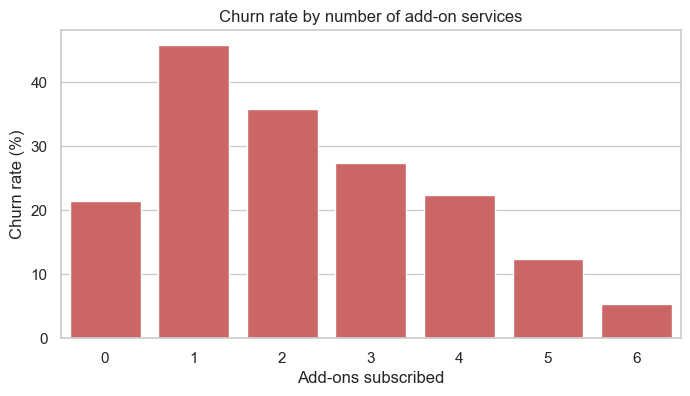

,customers,churn_rate,vs_overall_pts
num_addons,,,
0,2219,21.4,-5.1
1,966,45.8,19.3
2,1033,35.8,9.3
3,1118,27.4,0.9
4,852,22.3,-4.2
5,571,12.4,-14.1
6,284,5.3,-21.2


In [18]:
t = churn_by('num_addons').sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=t.index, y=t['churn_rate'], ax=ax, color='#dd5555')
ax.set(title='Churn rate by number of add-on services', xlabel='Add-ons subscribed', ylabel='Churn rate (%)')
plt.show()
t

## 5. Tenure, charges and churn

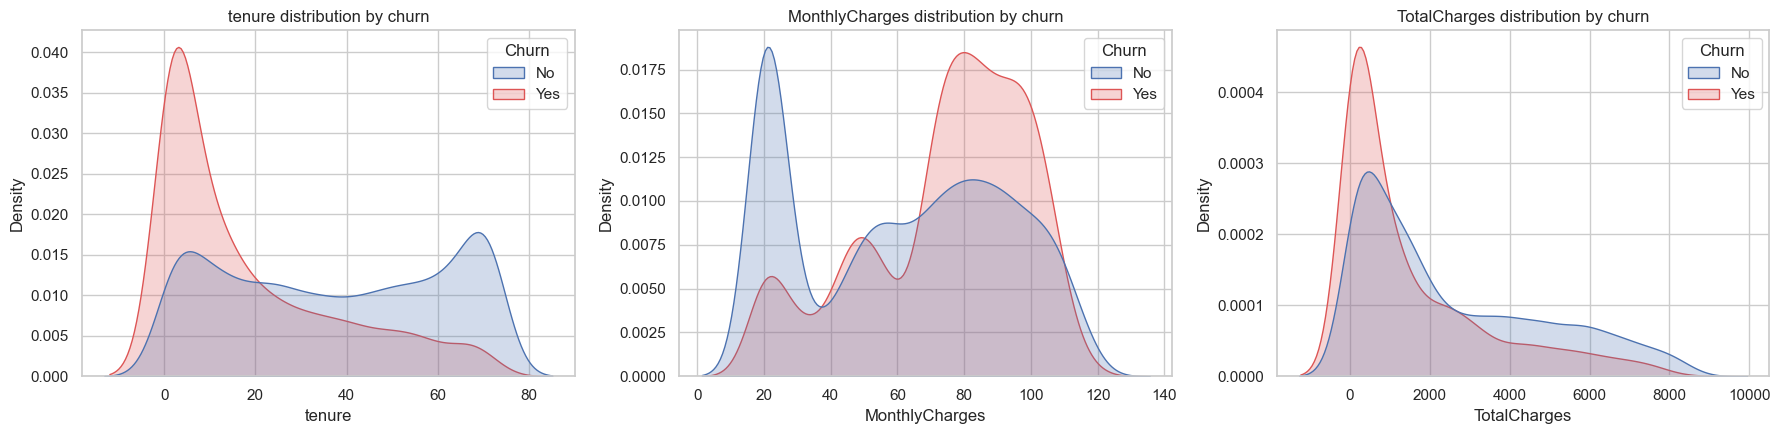

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.kdeplot(data=df, x=col, hue='Churn', common_norm=False, fill=True, palette=CHURN_COLORS, ax=ax)
    ax.set(title=f'{col} distribution by churn')
plt.tight_layout(); plt.show()

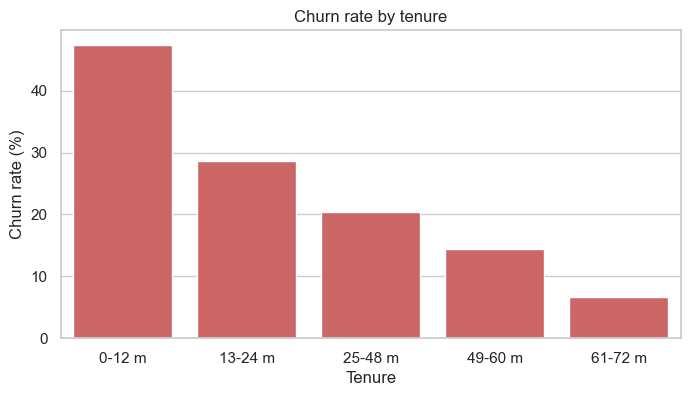

,customers,churn_rate,vs_overall_pts
tenure_group,,,
0-12 m,2186,47.4,20.9
13-24 m,1024,28.7,2.2
25-48 m,1594,20.4,-6.1
49-60 m,832,14.4,-12.1
61-72 m,1407,6.6,-19.9


In [20]:
t = churn_by('tenure_group').sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=t.index.astype(str), y=t['churn_rate'], ax=ax, color='#dd5555')
ax.set(title='Churn rate by tenure', xlabel='Tenure', ylabel='Churn rate (%)')
plt.show()
t

In [21]:
df['charge_band'] = pd.qcut(df['MonthlyCharges'], 4, labels=['Q1 low', 'Q2', 'Q3', 'Q4 high'])
churn_by('charge_band').sort_index().join(df.groupby('charge_band', observed=True)['MonthlyCharges'].agg(['min', 'max']))

,customers,churn_rate,vs_overall_pts,min,max
charge_band,,,,,
Q1 low,1762,11.2,-15.3,18.25,35.50
Q2,1766,24.6,-1.9,35.55,70.35
Q3,1757,37.5,11.0,70.40,89.85
Q4 high,1758,32.9,6.4,89.90,118.75


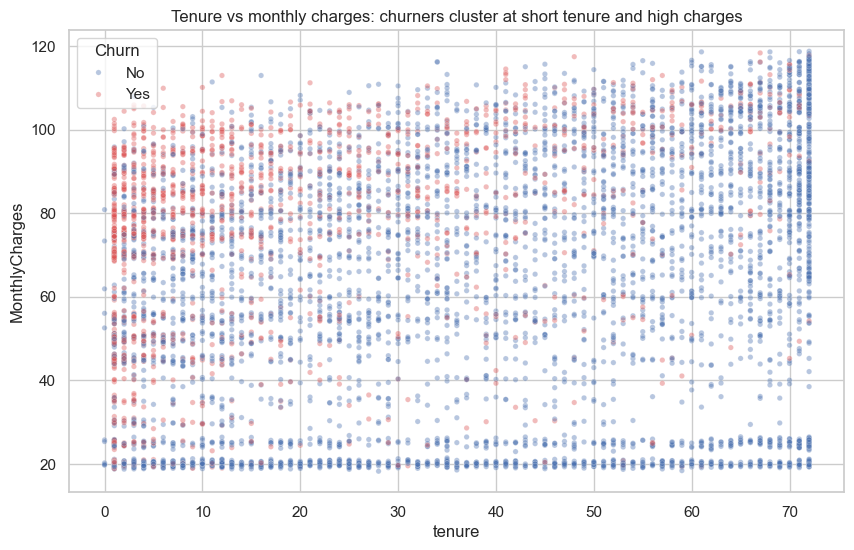

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn', palette=CHURN_COLORS, alpha=0.4, s=15, ax=ax)
ax.set(title='Tenure vs monthly charges: churners cluster at short tenure and high charges')
plt.show()

### 5.1 Internet service, contract and tenure together

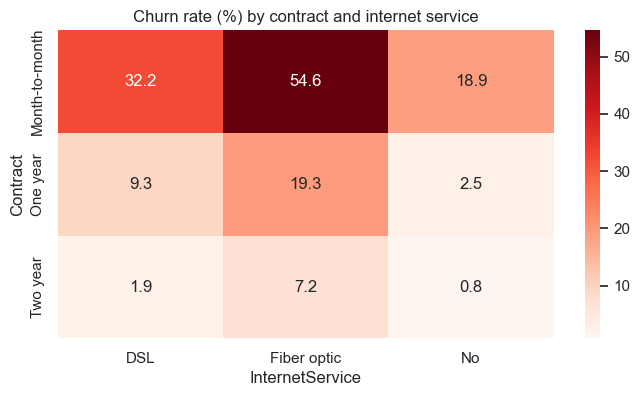

In [23]:
pivot = df.pivot_table(index='Contract', columns='InternetService', values='churn_flag', aggfunc='mean') * 100
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Reds', ax=ax)
ax.set_title('Churn rate (%) by contract and internet service')
plt.show()

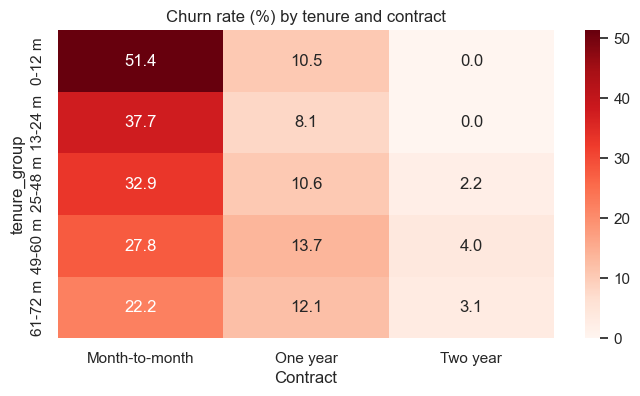

In [24]:
pivot2 = df.pivot_table(index='tenure_group', columns='Contract', values='churn_flag', aggfunc='mean', observed=True) * 100
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot2, annot=True, fmt='.1f', cmap='Reds', ax=ax)
ax.set_title('Churn rate (%) by tenure and contract')
plt.show()

In [25]:
fiber = df[df['InternetService'] == 'Fiber optic']
print('Fiber customers: median monthly charge', fiber['MonthlyCharges'].median(), '| DSL:', df[df['InternetService'] == 'DSL']['MonthlyCharges'].median())
fiber.groupby('TechSupport')['churn_flag'].mean().mul(100).round(1)

Fiber customers: median monthly charge 91.67500000000001 | DSL: 56.15


TechSupport
No     49.4
Yes    22.6
Name: churn_flag, dtype: float64

### 5.2 Correlation with churn

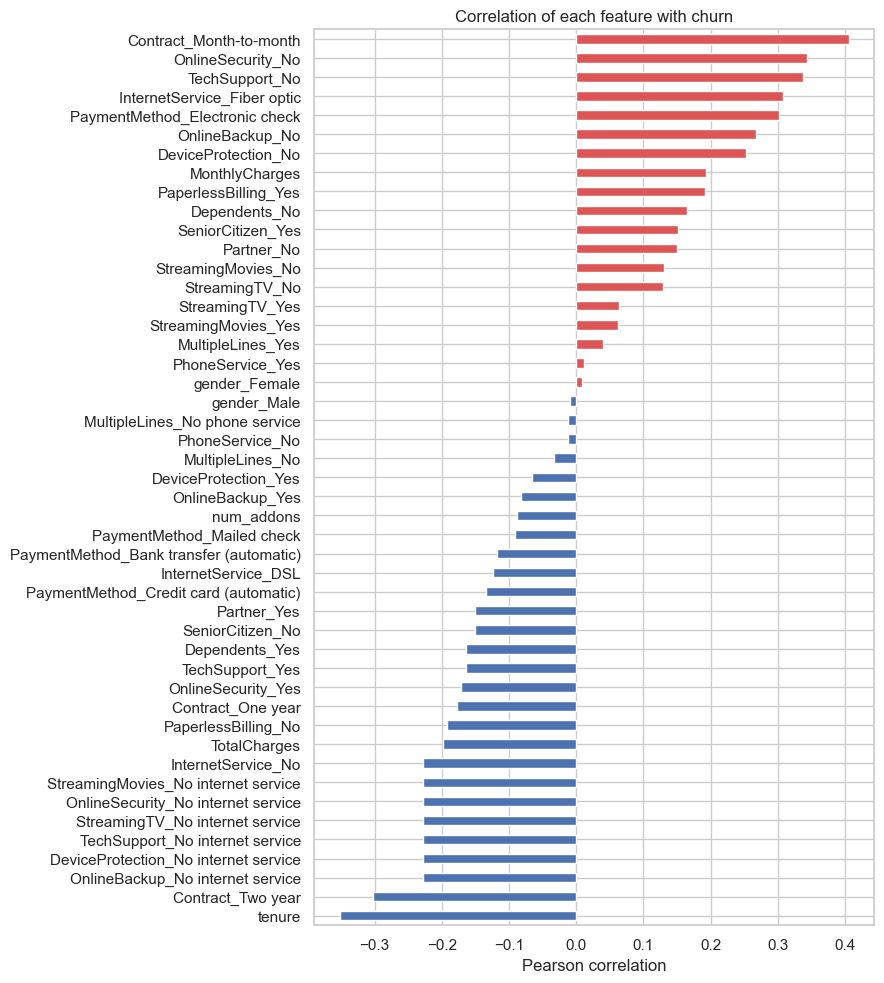

tenure                                 -0.352
Contract_Two year                      -0.302
OnlineBackup_No internet service       -0.228
DeviceProtection_No internet service   -0.228
TechSupport_No internet service        -0.228
StreamingTV_No internet service        -0.228
OnlineBackup_No                         0.268
PaymentMethod_Electronic check          0.302
InternetService_Fiber optic             0.308
TechSupport_No                          0.337
OnlineSecurity_No                       0.343
Contract_Month-to-month                 0.405
Name: churn_flag, dtype: float64

In [26]:
encoded = pd.get_dummies(df.drop(columns=['customerID', 'Churn', 'tenure_group', 'charge_band']), drop_first=False, dtype=int)
corr = encoded.corr()['churn_flag'].drop('churn_flag').sort_values()
fig, ax = plt.subplots(figsize=(9, 10))
corr.plot(kind='barh', ax=ax, color=np.where(corr > 0, '#dd5555', '#4c72b0'))
ax.set(title='Correlation of each feature with churn', xlabel='Pearson correlation')
plt.tight_layout(); plt.show()
pd.concat([corr.head(6), corr.tail(6)]).round(3)

## 6. High-churn segments

In [27]:
seg = (df.groupby(['Contract', 'InternetService', 'PaymentMethod'])['churn_flag']
         .agg(customers='size', churn_rate='mean').query('customers >= 100'))
seg['churn_rate'] = (seg['churn_rate'] * 100).round(1)
seg['churners'] = (seg['customers'] * seg['churn_rate'] / 100).round().astype(int)
seg.sort_values('churn_rate', ascending=False).head(8)

customers  \
Contract       InternetService PaymentMethod                          
Month-to-month Fiber optic     Electronic check                1307   
                               Mailed check                     201   
                               Bank transfer (automatic)        327   
                               Credit card (automatic)          293   
               DSL             Electronic check                 474   
                               Mailed check                     367   
                               Credit card (automatic)          185   
One year       Fiber optic     Electronic check                 196   

                                                          churn_rate  churners  
Contract       InternetService PaymentMethod                                    
Month-to-month Fiber optic     Electronic check                 60.4       789  
                               Mailed check                     50.7       102  
                               Bank transfer (automatic)        45.6       149  
                               Credit card (automatic)          41.6       122  
               DSL             Electronic check                 40.5       192  
                               Mailed check                     30.8       113  
                               Credit card (automatic)          27.0        50  
One year       Fiber optic     Electronic check                 26.0        51

In [28]:
high_risk = (df['Contract'] == 'Month-to-month') & (df['InternetService'] == 'Fiber optic') & (df['tenure'] <= 12)
print(f"Month-to-month + fiber + tenure <= 12 months: {high_risk.sum()} customers ({high_risk.mean():.1%} of base)")
print(f"  churn rate {df.loc[high_risk, 'churn_flag'].mean():.1%}, share of all churners {df.loc[high_risk, 'churn_flag'].sum() / df['churn_flag'].sum():.1%}")
lost_revenue = df.loc[df['churn_flag'] == 1, 'MonthlyCharges'].sum()
print(f"Monthly recurring revenue lost to churners: ${lost_revenue:,.0f} ({lost_revenue / df['MonthlyCharges'].sum():.1%} of total)")

Month-to-month + fiber + tenure <= 12 months: 916 customers (13.0% of base)
  churn rate 70.2%, share of all churners 34.4%
Monthly recurring revenue lost to churners: $139,131 (30.5% of total)


## 7. Key insights and conclusions

### Cleaning summary
- `TotalCharges` was stored as text and contained 11 blank values. All 11 belong to customers with tenure = 0 who have not been billed yet, so the blanks were set to 0 and the column was converted to a number.
- There are no other missing values, no duplicate rows and no duplicate customer IDs.
- `SeniorCitizen` was recoded from 0/1 to No/Yes.
- Three columns were added: a numeric churn flag, tenure groups (0–12, 13–24, 25–48, 49–60 and 61–72 months), and a count of add-on services (0–6).
- "No internet service" and "No phone service" were kept as their own categories, because these customers cannot buy the add-ons.

### Key findings
1. **Overall churn:** 26.5% of customers left (1,869 of 7,043). They account for $139,131 of monthly charges, which is **30.5% of monthly recurring revenue**. Churners therefore pay more than average.
2. **Contract type is the strongest factor:**
   - Month-to-month customers churn at 42.7%.
   - One-year contracts churn at 11.3%, and two-year contracts at only 2.8%.
   - Month-to-month contract has the highest correlation with churn of any feature (+0.41).
3. **Tenure:**
   - Churn is 47.4% in the first year and falls steadily to 6.6% after five years.
   - Churners have a median tenure of 10 months, against 38 months for customers who stayed.
4. **Charges:**
   - Churners pay more per month (median $79.6 vs $64.4).
   - The lowest charge quartile churns at 11.2%, while the $70–90 band churns at 37.5%.
5. **Internet service:**
   - Fiber-optic customers churn at 41.9%, compared with 19.0% for DSL and 7.4% for customers without internet.
   - Fiber is also much more expensive (median $91.7 vs $56.2 for DSL).
6. **Protective add-ons:** customers without Online Security (41.8%) or Tech Support (41.6%) churn about three times as often as those who have them (14.6% and 15.2%). Among fiber customers, adding Tech Support cuts churn from 49.4% to 22.6%.
7. **Number of add-ons:**
   - Churn peaks at 45.8% for customers with exactly one add-on and falls to 5.3% for customers with all six.
   - Customers with zero add-ons churn at only 21.4%, because most of them have no internet service.
8. **Payment and billing:**
   - Electronic check users churn at 45.3%. The other payment methods range from 15% to 19%.
   - Paperless billing customers churn at 33.6%, against 16.3% for paper billing.
9. **Demographics:**
   - Gender makes no difference (26.9% vs 26.2%).
   - Senior citizens churn at 41.7%.
   - Customers without a partner (33.0%) or without dependents (31.3%) churn more than those with a partner or dependents.

### High-churn segments
| Segment | Customers | Churn rate |
|---|---|---|
| Month-to-month + Fiber + Electronic check | 1,307 | **60.4%** (789 churners) |
| Month-to-month + Fiber + Mailed check | 201 | 50.7% |
| Month-to-month + Fiber + Bank transfer | 327 | 45.6% |
| Month-to-month + Fiber + **first 12 months** | 916 (13% of base) | **70.2%**, 34% of all churners |

### Retention strategies
- **Move customers to longer contracts.** Offer a discount or free upgrade for switching from month-to-month to a 1- or 2-year plan, especially during the first year.
- **Focus on onboarding in the first 12 months.** Run welcome calls and check-ins, and give extra attention to new fiber customers.
- **Bundle protective services.** Include Online Security and Tech Support free or at a discount for fiber customers, since these customers churn far less.
- **Review fiber pricing and quality.** High fiber churn at high prices suggests a value-for-money or service problem that needs investigation through surveys and network data.
- **Encourage automatic payment.** Give a small incentive to move from electronic check to card or bank auto-pay.
- **Target seniors and single-person households** with tailored plans and support.

### Limitations
- The data is a snapshot, so we only see whether a customer left in the last month.
- The findings are correlations. For example, fiber itself may not cause churn; price or service quality could.
- Features overlap with each other (for example, short tenure and month-to-month contracts), so a predictive model would be needed to measure each factor's separate effect.
